# Exploración del dataset Montgomery-Shenzhen

Exploración del dataset **Montgomery-Shenzhen** (versión de Kaggle de los conjuntos de la NLM; Jaeger et al., 2014; Candemir et al., 2014), que pasa a ser el conjunto de trabajo del proyecto. Ambas fuentes se usan juntas desde el inicio como un único dataset; TBX11K queda para una ampliación posterior.

El objetivo final es entrenar modelos de detección de tuberculosis (SVM, Random Forest y red neuronal) con **características radiómicas de primer orden** extraídas dentro de distintas segmentaciones pulmonares. Por eso la exploración se centra en lo que afecta a esas características: máscaras y posibles fuentes de sesgo.

Preguntas guía:
- ¿Qué contiene el dataset y cómo están organizadas imágenes, máscaras y lecturas clínicas?
- ¿Hay máscaras manuales atípicas que condicionen su uso como referencia?
- ¿Qué sesgos o confusores hay (fuente, edad, sexo, formato)?

### 1. Configuración del entorno

In [1]:
import hashlib
import re
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from tbseg.config import MS_INDEX_CSV, SEED, SEGTRAIN_RAW_DIR
from tbseg.segmentation.prepare import SOURCES, mask_path, patient_ids

IMG_DIR = SEGTRAIN_RAW_DIR / "CXR_png"
READ_DIR = SEGTRAIN_RAW_DIR / "ClinicalReadings"

rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 110)

# Colores fijos: clase (normal/TB) y fuente (Montgomery/Shenzhen)
CLASS_NAMES = {0: "normal", 1: "TB"}
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
SOURCE_ORDER = ["montgomery", "shenzhen"]
SOURCE_COLORS = {"montgomery": "#1baf7a", "shenzhen": "#4a3aa7"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "figure.dpi": 100,
})

### 2. Estructura del dataset

```
montgomery_shenzhen/
├── CXR_png/           radiografías  <prefijo>_<número>_<0|1>.png  (0 = normal, 1 = TB)
├── masks/             máscara de ambos pulmones (Shenzhen: <id>_mask.png, Montgomery: <id>.png)
├── ClinicalReadings/  sexo, edad y hallazgo radiológico por imagen (.txt)
└── NLM-*-ReadMe.*     documentación original de cada fuente
```

`MCUCXR` = Montgomery County (EE. UU.) y `CHNCXR` = Shenzhen (China). Los nombres de máscara se resuelven con `mask_path()` del módulo de preparación, el mismo que usa el entrenamiento de la U-Net.

#### 2.1 Correspondencia imagen-máscara-lectura

In [2]:
index = pd.DataFrame(
    {
        "image_id": p.stem,
        "source": SOURCES[p.stem.split("_")[0]],
        "tb": int(p.stem.endswith("_1")),
        "has_mask": mask_path(p.stem).exists(),
        "has_reading": (READ_DIR / f"{p.stem}.txt").exists(),
    }
    for p in sorted(IMG_DIR.glob("*.png"))
)

# Archivos de máscara o lectura que no tienen imagen
mask_ids = {p.stem.removesuffix("_mask") for p in (SEGTRAIN_RAW_DIR / "masks").glob("*.png")}
read_ids = {p.stem for p in READ_DIR.glob("*.txt")}
print(f"Imágenes: {len(index)} | con máscara: {index['has_mask'].sum()} | con lectura: {index['has_reading'].sum()}")
print(f"Máscaras sin imagen: {len(mask_ids - set(index['image_id']))} | lecturas sin imagen: {len(read_ids - set(index['image_id']))}")

counts = pd.crosstab(index["source"], index["tb"].map(CLASS_NAMES), margins=True, margins_name="total")
counts["% TB"] = (100 * counts["TB"] / counts["total"]).round(1)
counts

Imágenes: 704 | con máscara: 704 | con lectura: 704
Máscaras sin imagen: 0 | lecturas sin imagen: 0


tb,TB,normal,total,% TB
source,,,,
montgomery,58,80,138,42.0
shenzhen,287,279,566,50.7
total,345,359,704,49.0


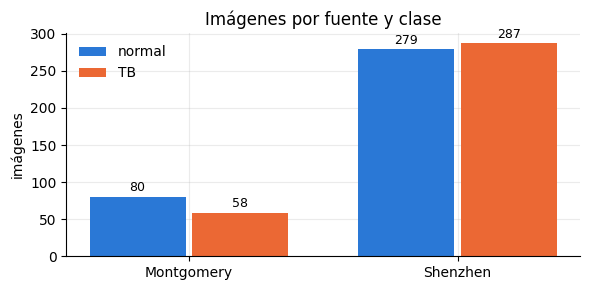

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
width = 0.38
x = np.arange(len(SOURCE_ORDER))
for k, (tb, name) in enumerate(CLASS_NAMES.items()):
    vals = [((index["source"] == s) & (index["tb"] == tb)).sum() for s in SOURCE_ORDER]
    bars = ax.bar(x + (k - 0.5) * width, vals, width * 0.94, color=CLASS_COLORS[tb], label=name)
    ax.bar_label(bars, padding=2, fontsize=9)
ax.set_xticks(x, [s.capitalize() for s in SOURCE_ORDER])
ax.set_ylabel("imágenes")
ax.set_title("Imágenes por fuente y clase")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- Las 704 radiografías tienen máscara y lectura clínica, sin archivos huérfanos.
- La versión original de Shenzhen trae 662 imágenes (326 normales, 336 TB); la de Kaggle conserva solo las **566 que tienen máscara**. Montgomery está completo (138).
- Shenzhen aporta el 80 % de las imágenes. Las dos clases quedan casi balanceadas en el conjunto, pero la proporción de TB es distinta en cada fuente.

### 3. Metadatos clínicos

Cada fuente usa un formato distinto de lectura:

- Montgomery: `Patient's Sex: F` / `Patient's Age: 027Y` / hallazgo (texto libre del radiólogo).
- Shenzhen: `male 45yrs` / hallazgo, con variantes como `femal`, `male, 35yrs`, `male 35yr` o `1month`.

In [4]:
SEX_CODES = {"m": "M", "male": "M", "f": "F", "female": "F", "femal": "F", "o": "O"}
AGE_UNITS = {"y": 1, "m": 1 / 12, "d": 1 / 365}


def parse_reading(text: str, source: str) -> dict:
    """Extrae sexo, edad (años) y hallazgo de una lectura clínica."""
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    if source == "montgomery":
        sex = re.search(r"Sex:\s*(\w)", text)
        age = re.search(r"Age:\s*(\d+)\s*([YMD])", text, re.I)
        finding = lines[2:]
    else:
        sex = re.match(r"(female|femal|male)", lines[0], re.I)
        age = re.search(r"(\d+)\s*(y|m|d)?", lines[0], re.I)
        finding = lines[1:]
    unit = (age.group(2) or "y").lower() if age else "y"
    return {
        "sex": SEX_CODES.get(sex.group(1).lower()) if sex else None,
        "age": round(int(age.group(1)) * AGE_UNITS[unit], 2) if age else np.nan,
        "finding": " | ".join(finding),
    }


meta = pd.DataFrame(
    [parse_reading((READ_DIR / f"{i}.txt").read_text(errors="replace"), s)
     for i, s in zip(index["image_id"], index["source"])]
)
index = pd.concat([index.drop(columns=["has_mask", "has_reading"]), meta], axis=1)

print("Lecturas sin sexo:", index["sex"].isna().sum(), "| sin edad:", index["age"].isna().sum())
print("Códigos de sexo:", index["sex"].value_counts().to_dict())
index.groupby("source").sample(3, random_state=SEED)[["image_id", "tb", "sex", "age", "finding"]]

Lecturas sin sexo: 0 | sin edad: 0
Códigos de sexo: {'M': 441, 'F': 262, 'O': 1}


,image_id,tb,sex,age,finding
655,MCUCXR_0150_1,1,M,32.0,extensive infiltrates bilaterally with large cavity in RUL and a moderate pleural effusion on the left. AF...
671,MCUCXR_0251_1,1,F,77.0,RUL fibrocavitary disease with volume loss and tracheal deviation to right; COPD scoliosis;
578,MCUCXR_0019_0,0,M,33.0,normal
396,CHNCXR_0465_1,1,M,24.0,Bilateral secondary PTB
302,CHNCXR_0371_1,1,M,40.0,PTB in the right upper field
435,CHNCXR_0526_1,1,M,63.0,bilateral PTB


#### 3.1 Pacientes repetidos

Algunas lecturas de Montgomery dicen *"same pt as MCUCXR_…"*: son controles del **mismo paciente** en momentos distintos. Si esas imágenes caen en particiones distintas habrá fuga de información, así que se asigna un `patient_id` común con `patient_ids()` de `prepare.py`, la misma función que agrupa por paciente la partición de la segmentación.

In [5]:
index["patient_id"] = index["image_id"].map(patient_ids(index["image_id"]))

repeated = index[index.duplicated("patient_id", keep=False)].sort_values("patient_id")
print(f"Imágenes con paciente repetido: {len(repeated)} en {repeated['patient_id'].nunique()} pacientes")
repeated[["image_id", "patient_id", "tb", "sex", "age", "finding"]]

Imágenes con paciente repetido: 5 en 2 pacientes


,image_id,patient_id,tb,sex,age,finding
648,MCUCXR_0113_1,MCUCXR_0113_1,1,F,84.0,bilateral miliary nodules diffusely with RML infiltrate and right pleural effusion; an old calcified granu...
649,MCUCXR_0117_1,MCUCXR_0113_1,1,F,85.0,stable CXR since 6M; off Rx since 6M (same pt as MCUCXR_0113_1)
656,MCUCXR_0162_1,MCUCXR_0162_1,1,M,49.0,RUL apical fibrotic disease with some calcifications; extensive irregular infiltrates in left lung with a ...
657,MCUCXR_0166_1,MCUCXR_0162_1,1,M,49.0,NO REPORT (same pt as MCUCXR_0162_1)
658,MCUCXR_0170_1,MCUCXR_0162_1,1,M,49.0,"CXR similar to prior views 1M and 2M ago with some slight improvement; on HRZ(E)x2 months, AFB smears neg ..."


#### 3.2 Sexo y edad

Sexo y edad no entran en los modelos. Se resumen de forma descriptiva para la tabla de datos del informe.

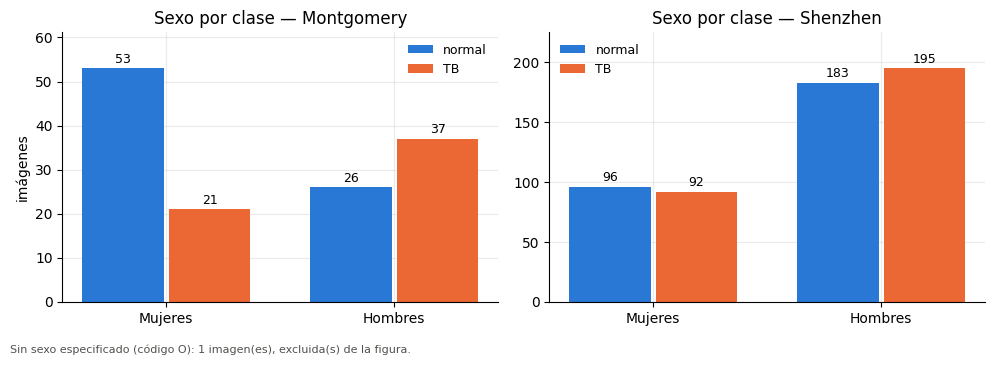

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
SEX_LABELS = {"F": "Mujeres", "M": "Hombres"}
width = 0.38
x = np.arange(len(SEX_LABELS))
for ax, source in zip(axes, SOURCE_ORDER):
    sub = index[index["source"] == source]
    for k, (tb, name) in enumerate(CLASS_NAMES.items()):
        vals = [((sub["sex"] == sex) & (sub["tb"] == tb)).sum() for sex in SEX_LABELS]
        bars = ax.bar(x + (k - 0.5) * width, vals, width * 0.94, color=CLASS_COLORS[tb], label=name)
        ax.bar_label(bars, padding=2, fontsize=9)
    ax.set_xticks(x, list(SEX_LABELS.values()))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.set_title(f"Sexo por clase — {source.capitalize()}")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("imágenes")

n_other = (~index["sex"].isin(SEX_LABELS)).sum()
fig.text(0.01, 0.005, f"Sin sexo especificado (código O): {n_other} imagen(es), excluida(s) de la figura.",
         fontsize=8, color="#52514e")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [7]:
demo = index.groupby(["source", "tb"]).agg(
    n=("image_id", "size"),
    mujeres=("sex", lambda s: (s == "F").sum()),
    hombres=("sex", lambda s: (s == "M").sum()),
    edad_mediana=("age", "median"),
    edad_q1=("age", lambda s: s.quantile(0.25)),
    edad_q3=("age", lambda s: s.quantile(0.75)),
).rename(index=CLASS_NAMES, level=1)
demo["% mujeres"] = (100 * demo["mujeres"] / demo["n"]).round(1)
demo["% hombres"] = (100 * demo["hombres"] / demo["n"]).round(1)
demo["edad, mediana (RIC)"] = [f"{m:.1f} ({a:.0f}-{b:.0f})" for m, a, b in demo[["edad_mediana", "edad_q1", "edad_q3"]].values]
demo[["n", "% mujeres", "% hombres", "edad, mediana (RIC)"]]

n  % mujeres  % hombres edad, mediana (RIC)
source     tb                                                   
montgomery normal   80       66.2       32.5        33.5 (22-46)
           TB       58       36.2       63.8        47.0 (32-61)
shenzhen   normal  279       34.4       65.6        32.0 (25-42)
           TB      287       32.1       67.9        34.0 (27-45)

- Se pudieron extraer sexo y edad de las 704 lecturas. Hay un paciente de Montgomery con sexo `O` (sin especificar).
- En Montgomery los casos TB son más a menudo hombres (64 % frente a 32,5 %) y mayores (mediana 47 frente a 33,5 años). En Shenzhen ambas clases tienen una composición parecida.
- Sexo y edad son propiedades del paciente: afectan por igual a todos los métodos de segmentación, así que no sesgan la comparación entre ellos. Se reportan solo como descripción del dataset.

### 4. Imágenes

#### 4.1 Ejemplos con su máscara

Tres radiografías normales y tres con TB por fuente, con el contorno de la máscara manual. En Montgomery se incluye `MCUCXR_0182_1` (TB pleural), el ejemplo de la presentación de U-Net.

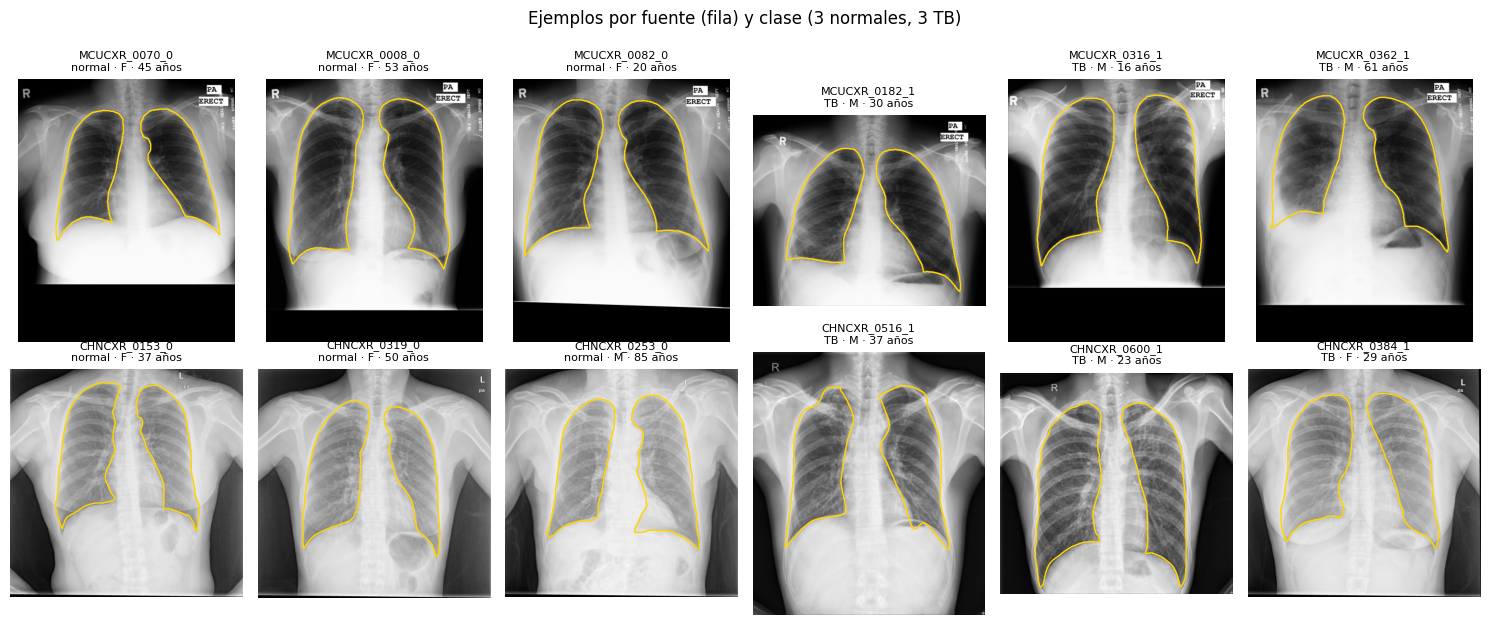

In [8]:
def load_pair(image_id: str, size: int = 512):
    img = cv2.imread(str(IMG_DIR / f"{image_id}.png"), cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(str(mask_path(image_id)), cv2.IMREAD_GRAYSCALE)
    scale = size / max(img.shape)
    dsize = (round(img.shape[1] * scale), round(img.shape[0] * scale))
    return cv2.resize(img, dsize, interpolation=cv2.INTER_AREA), cv2.resize(mask, dsize, interpolation=cv2.INTER_AREA) > 127


def show_with_mask(ax, image_id, title=None):
    img, mask = load_pair(image_id)
    ax.imshow(img, cmap="gray")
    ax.contour(mask, levels=[0.5], colors=["#ffd400"], linewidths=1)
    ax.set_title(title or image_id, fontsize=8)
    ax.axis("off")


examples = []
for source in SOURCE_ORDER:
    for tb in CLASS_NAMES:
        ids = index.query("source == @source and tb == @tb")["image_id"].to_numpy()
        chosen = list(rng.choice(ids, 3, replace=False))
        if source == "montgomery" and tb == 1 and "MCUCXR_0182_1" not in chosen:
            chosen[0] = "MCUCXR_0182_1"
        examples.append((source, tb, chosen))

fig, axes = plt.subplots(2, 6, figsize=(15, 6.2))
for r, source in enumerate(SOURCE_ORDER):
    ids = [(tb, i) for s, tb, chosen in examples if s == source for i in chosen]
    for c, (tb, image_id) in enumerate(ids):
        row = index.set_index("image_id").loc[image_id]
        show_with_mask(axes[r, c], image_id, f"{image_id}\n{CLASS_NAMES[tb]} · {row['sex']} · {row['age']:.0f} años")
plt.suptitle("Ejemplos por fuente (fila) y clase (3 normales, 3 TB)", y=1.0)
plt.tight_layout()
plt.show()

#### 4.2 Lectura y formato

La celda siguiente lee las 704 imágenes y sus máscaras **una sola vez**, en resolución completa (unos 3 minutos), y guarda lo que usan las secciones siguientes:

- formato de cada imagen (tamaño, canales) → esta sección;
- reparto del pulmón entre las dos mitades de la imagen → sección 5;
- md5 de los píxeles → sección 6.

In [9]:
def analyze(image_id: str):
    raw = cv2.imread(str(IMG_DIR / f"{image_id}.png"), cv2.IMREAD_UNCHANGED)
    mask_raw = cv2.imread(str(mask_path(image_id)), cv2.IMREAD_GRAYSCALE)
    channels = 1 if raw.ndim == 2 else raw.shape[2]
    same_channels = channels == 1 or all(np.array_equal(raw[..., 0], raw[..., c]) for c in range(1, channels))
    gray = raw if raw.ndim == 2 else cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY)
    lung = mask_raw > 127
    h, w = gray.shape

    # Reparto del pulmón entre las dos mitades de la imagen (izquierda / total)
    left_share = lung[:, : w // 2].sum() / lung.sum()

    record = {
        "image_id": image_id,
        "height": h, "width": w,
        "channels": channels, "same_channels": same_channels,
        "dtype": str(raw.dtype),
        "lung_area_frac": lung.mean(),
        "left_share": left_share,
        "md5": hashlib.md5(gray.tobytes()).hexdigest(),
    }
    return record


# cv2 libera el GIL al leer PNG: unos pocos hilos aceleran la pasada sin disparar la memoria
with ThreadPoolExecutor(max_workers=4) as pool:
    results = list(tqdm(pool.map(analyze, index["image_id"]), total=len(index), desc="Analizando imágenes"))

img_stats = pd.DataFrame(results)
index = index.merge(img_stats, on="image_id")
index["orientation"] = np.where(index["height"] >= index["width"], "vertical", "horizontal")
index.shape

Analizando imágenes:   0%|          | 0/704 [00:00<?, ?it/s]

(704, 16)

In [10]:
fmt = index.groupby("source").agg(
    imagenes=("image_id", "size"),
    canales=("channels", lambda s: sorted(s.unique())),
    canales_identicos=("same_channels", "all"),
    tipo=("dtype", lambda s: sorted(s.unique())),
    alto_px=("height", lambda s: f"{s.min()}-{s.max()}"),
    ancho_px=("width", lambda s: f"{s.min()}-{s.max()}"),
)
fmt.T

source,montgomery,shenzhen
imagenes,138,566
canales,[1],[3]
canales_identicos,True,True
tipo,[uint8],[uint8]
alto_px,4020-4892,989-3001
ancho_px,4020-4892,1225-3001


- **Canales:** Montgomery viene en un canal y Shenzhen en tres canales idénticos. Se pueden leer en escala de grises sin perder información.
- **Profundidad:** ambas fuentes vienen en 8 bits (`uint8`). El ReadMe de Montgomery habla de 12 bits, así que esta versión ya fue reducida a 8.
- **Tamaño:** Montgomery mide siempre 4020×4892 (vertical u horizontal), con un píxel de 0,0875 mm. Shenzhen varía entre ~1000 y 3000 px de lado y su ReadMe no informa el espaciado de píxel.

### 5. Máscaras atípicas

Las máscaras de Montgomery se dibujaron bajo supervisión de un radiólogo: incluyen ambos pulmones.

**Cómo se buscan las máscaras raras.** Se parte la imagen en dos mitades con una línea vertical por el centro y se mide qué porcentaje del pulmón marcado cae en la mitad izquierda.

- En una máscara normal el resultado es un poco más del 50 % (mediana: 54 %). La mitad derecha de la imagen tiene algo menos de pulmón porque ahí está el corazón.
- Si a un pulmón le falta un trozo grande, el porcentaje se aleja mucho del 54 %: hacia 90 % si falta pulmón a la derecha, o hacia 30 % si falta a la izquierda.

No se fija ningún umbral: se muestran las 6 máscaras más alejadas del 54 % y se revisan a ojo.

In [11]:
N_SHOW = 6  # máscaras a revisar

q1, med, q3 = index["left_share"].quantile([0.25, 0.5, 0.75])
print(f"Pulmón en la mitad izquierda: mediana {100 * med:.0f} % (Q1-Q3: {100 * q1:.0f}-{100 * q3:.0f} %)")
extremes = index.loc[(index["left_share"] - med).abs().nlargest(N_SHOW).index]
extremes[["image_id", "tb", "left_share", "finding"]].assign(
    left_share=lambda d: (100 * d["left_share"]).round(1)
).rename(columns={"left_share": "mitad izq. %"})

Pulmón en la mitad izquierda: mediana 54 % (Q1-Q3: 52-56 %)


,image_id,tb,mitad izq. %,finding
506,CHNCXR_0603_1,1,90.7,bilateral PTB
509,CHNCXR_0606_1,1,79.1,bilateral PTB
563,CHNCXR_0660_1,1,31.4,1.bilateral secondary PTB with right upper atelectasis;2.right pleural adhesions;3.left compensatory emph...
301,CHNCXR_0370_1,1,73.2,"bilateral PTB, with left pleural effusion"
292,CHNCXR_0361_1,1,73.1,"Bilateral secondary PTB, left encapsulated intrathoracic fluid"
422,CHNCXR_0513_1,1,34.9,Right PTB


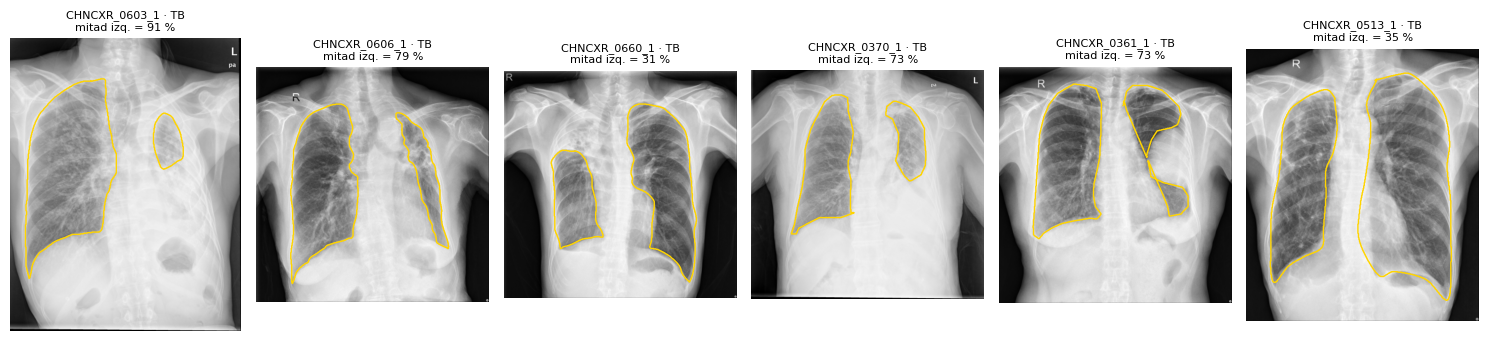

In [12]:
fig, axes = plt.subplots(1, N_SHOW, figsize=(2.5 * N_SHOW, 3.3))
for ax, row in zip(axes, extremes.itertuples()):
    show_with_mask(ax, row.image_id, f"{row.image_id} · {CLASS_NAMES[row.tb]}\nmitad izq. = {100 * row.left_share:.0f} %")
plt.tight_layout()
plt.show()

- Las 6 máscaras más extremas son casos TB de Shenzhen en los que un pulmón quedó muy recortado (en `CHNCXR_0603_1` la mitad izquierda concentra el 91 % del pulmón). En tres de ellas la lectura menciona derrame, atelectasia o líquido encapsulado; en las otras tres solo dice PTB. En esas máscaras se **delimita solo el pulmón aireado visible**. El ReadMe de Montgomery, en cambio, indica que ante patología severa se dibuja el borde *inferido*. Las máscaras de Shenzhen no vienen de la NLM: se agregaron en la versión de Kaggle y no traen documentación de su convención. Así, **la convención de anotación difiere entre fuentes**, y eso afecta directamente el área y las características extraídas en los casos más graves.

### 6. Duplicados

El md5 de los píxeles detecta copias exactas aunque el PNG esté codificado distinto.

In [13]:
exact = index[index.duplicated("md5", keep=False)]
print(f"Grupos de duplicados exactos: {exact['md5'].nunique()} ({len(exact)} imágenes)")
print(f"{len(index)} imágenes de {index['patient_id'].nunique()} pacientes")

Grupos de duplicados exactos: 0 (0 imágenes)
704 imágenes de 701 pacientes


- No hay duplicados exactos.
- La única repetición conocida son los 2 pacientes de Montgomery con varias radiografías (sección 3.1), agrupados con `patient_id`.

### 7. Índice de salida

Se guarda un índice con una fila por imagen para las fases siguientes (segmentación, extracción de características y protocolo de entrenamiento). No incluye particiones: los folds se definen con el protocolo de entrenamiento, agrupando por `patient_id`.

In [14]:
INDEX_COLS = ["image_id", "patient_id", "source", "tb", "sex", "age", "finding", "height", "width",
              "orientation", "channels", "lung_area_frac", "left_share", "md5"]
out = index[INDEX_COLS].copy()
out["lung_area_frac"] = out["lung_area_frac"].round(4)
out["left_share"] = out["left_share"].round(4)
MS_INDEX_CSV.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(MS_INDEX_CSV, index=False)
print(f"Guardado {MS_INDEX_CSV.relative_to(MS_INDEX_CSV.parents[2])}: {out.shape}")
out.head()

Guardado data/metadata/montgomery_shenzhen_index.csv: (704, 14)


,image_id,patient_id,source,tb,sex,age,finding,height,width,orientation,channels,lung_area_frac,left_share,md5
0,CHNCXR_0001_0,CHNCXR_0001_0,shenzhen,0,M,45.0,normal,2919,3000,horizontal,3,0.2455,0.4896,cb9e6ba843d512a5719fef8f6a4cd834
1,CHNCXR_0002_0,CHNCXR_0002_0,shenzhen,0,M,63.0,normal,2951,3000,horizontal,3,0.2167,0.4546,c238805cf0210c984a6b81bb908fb18b
2,CHNCXR_0003_0,CHNCXR_0003_0,shenzhen,0,F,48.0,normal,2945,2987,horizontal,3,0.2393,0.5122,c1236e360b37974a4170f5f209836c39
3,CHNCXR_0004_0,CHNCXR_0004_0,shenzhen,0,M,58.0,normal,2933,3000,horizontal,3,0.2229,0.5245,85694b4fbd129c2ec9de786093c250a4
4,CHNCXR_0005_0,CHNCXR_0005_0,shenzhen,0,M,28.0,normal,2933,3000,horizontal,3,0.2382,0.5338,10169ed9e6b0071b65bcfbc97f56fbd8


### 8. Conclusiones e implicaciones para el proyecto

**Datos utilizables**
- Hay 704 radiografías con máscara pulmonar manual y lectura clínica: 345 TB y 359 normales. Montgomery aporta 138 y Shenzhen 566.
- No hay duplicados exactos. La única repetición es la de 2 pacientes de Montgomery con varias radiografías (5 imágenes), registrada en `patient_id`.
- El índice queda en `data/metadata/montgomery_shenzhen_index.csv`, con metadatos clínicos, de formato y de máscara.

**Preprocesado necesario antes de extraer características**
- Leer en escala de grises de 1 canal: no se pierde información en ninguna de las dos fuentes.
- Llevar todas las imágenes a una resolución común. Los tamaños y espaciados difieren entre fuentes, y Shenzhen no informa el espaciado.

**Sesgos y confusores**
- **Fuente:** las dos fuentes difieren en formato, tamaño y adquisición. Las métricas deben reportarse globalmente y también por fuente.
- **Edad y sexo en Montgomery:** los pacientes TB son mayores y más a menudo hombres. Afectan por igual a todos los métodos de segmentación, así que no sesgan la comparación; se reportan en la descripción del dataset.
- **Etiqueta TB heterogénea:** según las lecturas clínicas (columna `finding` del índice), la clase TB incluye casos activos, curados y en tratamiento.